# Segmenter et compresser des données : K-Means et analyse en composantes principales

**Franck Nankeng** · Projet de machine learning non supervisé · Python, scikit-learn

> *English summary — Two unsupervised learning studies. (1) A small salary/age dataset shows how an unscaled feature
> silently drives K-Means. (2) On 1,797 handwritten digits (64 pixels each), PCA keeps 95 % of the variance with far fewer
> dimensions; I measure what this costs in classification accuracy, and how well K-Means recovers the ten digits without labels.*

**Pourquoi ce projet.** En entreprise, on dispose souvent de données sans étiquette : clients, transactions, tickets.
Deux questions reviennent : *peut-on former des groupes homogènes ?* et *peut-on réduire le nombre de variables sans
perdre l'information utile ?* Ce notebook répond aux deux, en mesurant chaque fois l'effet de mes choix.

*Exercice construit à partir de cas vus en formation (cours d'IA du Pr M. Youssfi), que j'ai restructuré et
complété par mes propres expériences (effet de l'échelle, coût de la compression, comparaison aux vraies étiquettes).*

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.datasets import load_digits

SEED = 42
NAVY, SAFFRON, GREY = "#14213D", "#E8962E", "#8A93A6"
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

## Partie A — Le piège de l'échelle dans K-Means

Jeu de données : âge et salaire mensuel de 22 personnes. K-Means regroupe les points selon une **distance
euclidienne** : si une variable s'exprime en milliers (salaire) et l'autre en dizaines (âge), la première
écrase la seconde.

In [2]:
sal = pd.read_csv("../data/salaires.csv")
X_sal = sal[["Age", "Salary"]]
sal.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Age,22.0,34.8,5.9,26.0,29.0,36.5,39.8,43.0
Salary,22.0,9027.3,4340.6,4500.0,5850.0,6750.0,13525.0,16000.0


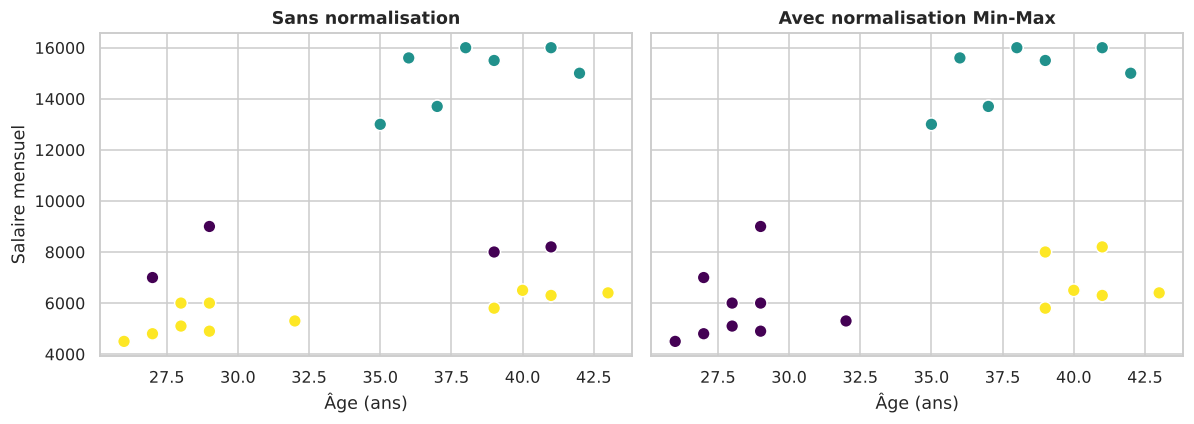

Silhouette (calculée sur données normalisées) — sans normalisation : 0.252
Silhouette (calculée sur données normalisées) — avec normalisation : 0.714
Accord entre les deux segmentations (ARI, 1 = identiques) : 0.475


In [3]:
brut = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit_predict(X_sal)
norm = Pipeline([("echelle", MinMaxScaler()),
                 ("kmeans", KMeans(n_clusters=3, n_init=10, random_state=SEED))]).fit_predict(X_sal)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, lab, titre in zip(axes, [brut, norm], ["Sans normalisation", "Avec normalisation Min-Max"]):
    ax.scatter(sal["Age"], sal["Salary"], c=lab, cmap="viridis", s=70, edgecolor="white")
    ax.set_title(titre); ax.set_xlabel("Âge (ans)")
axes[0].set_ylabel("Salaire mensuel")
plt.tight_layout(); plt.show()

X_mm = MinMaxScaler().fit_transform(X_sal)
print(f"Silhouette (calculée sur données normalisées) — sans normalisation : {silhouette_score(X_mm, brut):.3f}")
print(f"Silhouette (calculée sur données normalisées) — avec normalisation : {silhouette_score(X_mm, norm):.3f}")
print(f"Accord entre les deux segmentations (ARI, 1 = identiques) : {adjusted_rand_score(brut, norm):.3f}")

**Lecture.** Sans normalisation, les groupes sont de simples tranches de salaire : l'âge n'intervient presque pas.
Une fois les deux variables ramenées sur [0, 1], les groupes tiennent compte des deux dimensions et deviennent
plus compacts. Normaliser n'est pas un détail technique : c'est une décision qui change la segmentation remise aux métiers.

## Partie B — Chiffres manuscrits : compresser 64 dimensions

Jeu de données : 1 797 images de chiffres de 0 à 9, de 8 × 8 pixels, soit **64 variables** par image.

(1797, 64) | classes : [178 182 177 183 181 182 181 179 174 180]


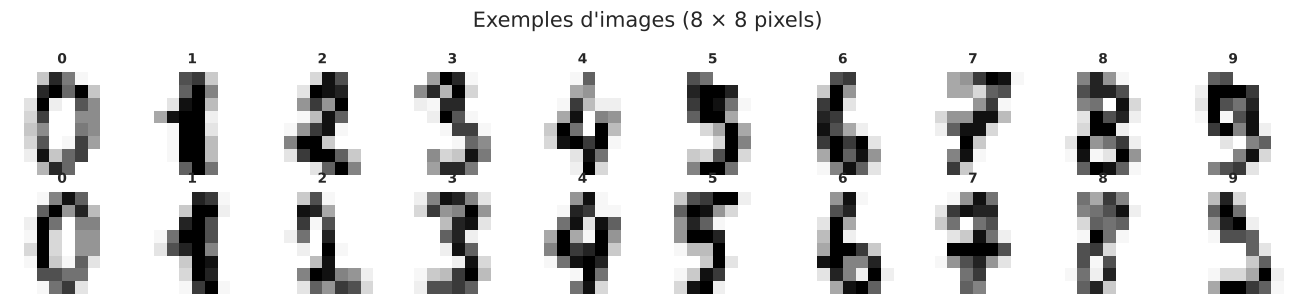

In [4]:
digits = load_digits()
X, y = digits.data, digits.target
print(X.shape, "| classes :", np.bincount(y))

fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X[i].reshape(8, 8), cmap="Greys"); ax.set_title(y[i], fontsize=9); ax.axis("off")
plt.suptitle("Exemples d'images (8 × 8 pixels)"); plt.tight_layout(); plt.show()

### B1. Combien de composantes faut-il garder ?

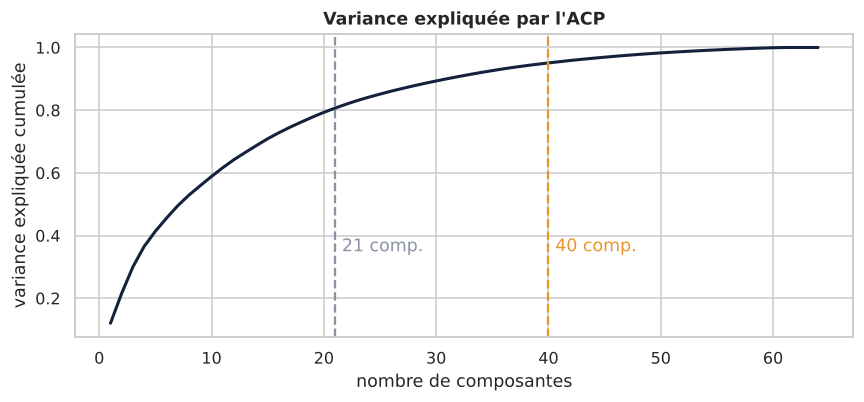

80 % de la variance : 21 composantes | 95 % : 40 composantes sur 64


In [5]:
X_std = StandardScaler().fit_transform(X)
acp = PCA().fit(X_std)
cumul = np.cumsum(acp.explained_variance_ratio_)
n95 = int(np.argmax(cumul >= 0.95) + 1)
n80 = int(np.argmax(cumul >= 0.80) + 1)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(range(1, 65), cumul, color=NAVY, lw=2)
for n, c in [(n80, GREY), (n95, SAFFRON)]:
    ax.axvline(n, ls="--", color=c); ax.text(n + 0.6, 0.35, f"{n} comp.", color=c)
ax.set_xlabel("nombre de composantes"); ax.set_ylabel("variance expliquée cumulée")
ax.set_title("Variance expliquée par l'ACP"); plt.tight_layout(); plt.show()
print(f"80 % de la variance : {n80} composantes | 95 % : {n95} composantes sur 64")

### B2. Que coûte la compression pour un classifieur ?

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
configs = {
    "64 pixels (sans ACP)": Pipeline([("std", StandardScaler()),
                                      ("lr", LogisticRegression(max_iter=3000))]),
    f"ACP 95 % ({n95} comp.)": Pipeline([("std", StandardScaler()), ("acp", PCA(n_components=0.95)),
                                        ("lr", LogisticRegression(max_iter=3000))]),
    f"ACP 80 % ({n80} comp.)": Pipeline([("std", StandardScaler()), ("acp", PCA(n_components=0.80)),
                                        ("lr", LogisticRegression(max_iter=3000))]),
    "ACP 2 composantes": Pipeline([("std", StandardScaler()), ("acp", PCA(n_components=2)),
                                   ("lr", LogisticRegression(max_iter=3000))]),
}
lignes = []
for nom, pipe in configs.items():
    t0 = time.perf_counter()
    s = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy")
    lignes.append({"configuration": nom, "exactitude moyenne": s.mean(), "écart-type": s.std(),
                   "temps (s)": time.perf_counter() - t0})
comparaison = pd.DataFrame(lignes).set_index("configuration")
comparaison.round(3)

,exactitude moyenne,écart-type,temps (s)
configuration,,,
64 pixels (sans ACP),0.971,0.004,0.164
ACP 95 % (40 comp.),0.968,0.004,0.569
ACP 80 % (21 comp.),0.947,0.003,0.516
ACP 2 composantes,0.549,0.013,0.345


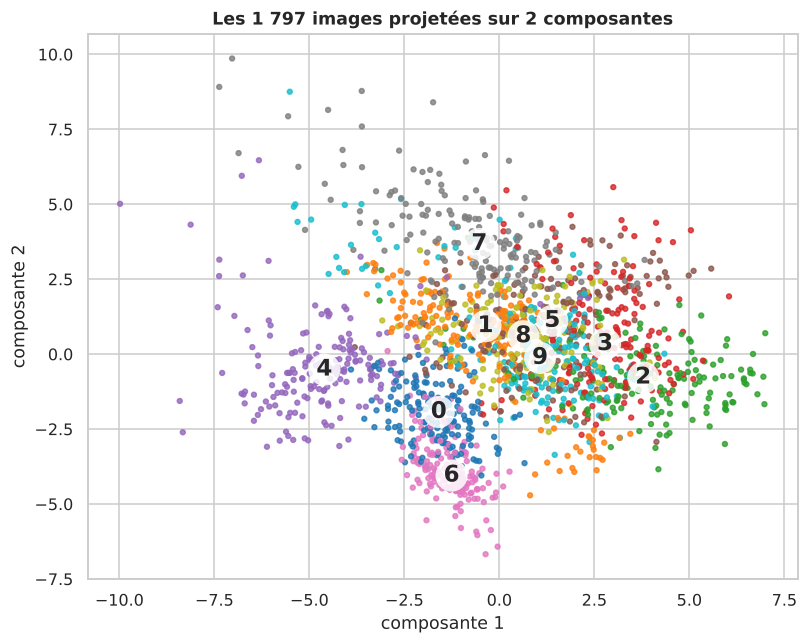

In [7]:
proj = PCA(n_components=2).fit_transform(X_std)
fig, ax = plt.subplots(figsize=(7.5, 6))
sc = ax.scatter(proj[:, 0], proj[:, 1], c=y, cmap="tab10", s=10, alpha=0.8)
for d in range(10):
    cx, cy = np.median(proj[y == d], axis=0)
    ax.text(cx, cy, str(d), fontsize=15, weight="bold", ha="center", va="center",
            bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec="none", alpha=0.85))
ax.set_xlabel("composante 1"); ax.set_ylabel("composante 2")
ax.set_title("Les 1 797 images projetées sur 2 composantes"); plt.tight_layout(); plt.show()

### B3. K-Means retrouve-t-il les dix chiffres sans les étiquettes ?

Dans la partie A, normaliser améliorait la segmentation. Ici, tous les pixels partagent déjà la même échelle (0 à 16).
Je teste donc les deux options au lieu d'appliquer la règle par réflexe : K-Means sur les pixels bruts compressés par ACP,
et K-Means sur les pixels standardisés puis compressés.

In [8]:
representations = {
    "pixels bruts + ACP 95 %": PCA(n_components=0.95, random_state=SEED).fit_transform(X),
    "pixels standardisés + ACP 95 %": PCA(n_components=0.95, random_state=SEED).fit_transform(X_std),
}
lignes, labels = [], {}
for nom, R in representations.items():
    km = KMeans(n_clusters=10, n_init=20, random_state=SEED).fit(R)
    t = pd.crosstab(y, km.labels_)
    labels[nom] = km.labels_
    lignes.append({"représentation": nom, "dimensions": R.shape[1],
                   "ARI (1 = parfait)": adjusted_rand_score(y, km.labels_),
                   "pureté des groupes": t.max(axis=0).sum() / len(y)})
pd.DataFrame(lignes).set_index("représentation").round(3)

,dimensions,ARI (1 = parfait),pureté des groupes
représentation,,,
pixels bruts + ACP 95 %,29,0.669,0.794
pixels standardisés + ACP 95 %,40,0.467,0.623


Standardiser les pixels donne autant de poids aux pixels du bord, presque toujours blancs, qu'aux pixels qui dessinent
le chiffre : leur bruit est amplifié et la segmentation se dégrade. Je retiens donc les pixels bruts.

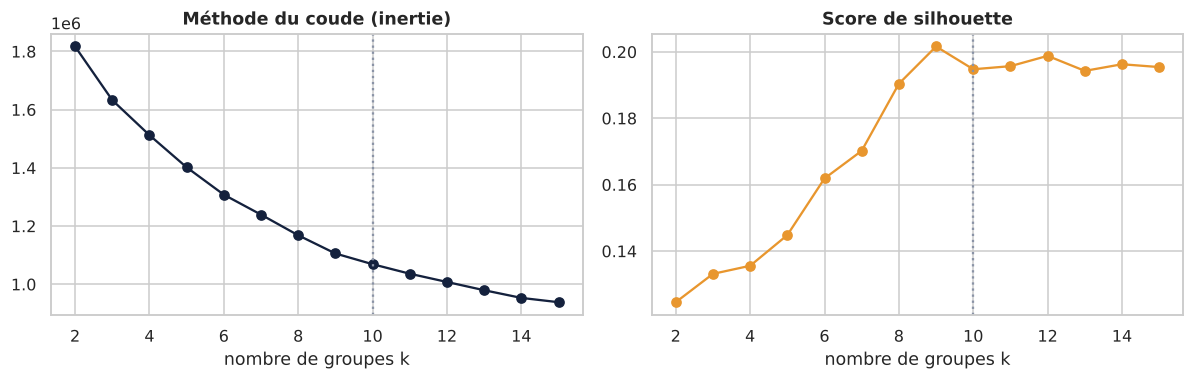

In [9]:
X_red = representations["pixels bruts + ACP 95 %"]
ks = range(2, 16)
inerties, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_red)
    inerties.append(km.inertia_); silhouettes.append(silhouette_score(X_red, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(ks, inerties, "o-", color=NAVY); axes[0].set_title("Méthode du coude (inertie)")
axes[1].plot(ks, silhouettes, "o-", color=SAFFRON); axes[1].set_title("Score de silhouette")
for ax in axes: ax.set_xlabel("nombre de groupes k"); ax.axvline(10, ls=":", color=GREY)
plt.tight_layout(); plt.show()

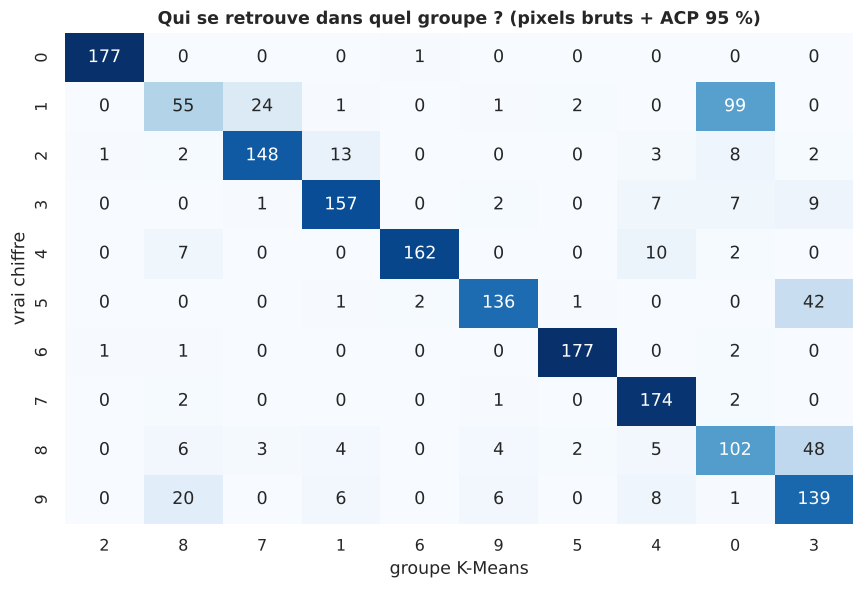

In [10]:
table = pd.crosstab(pd.Series(y, name="vrai chiffre"),
                    pd.Series(labels["pixels bruts + ACP 95 %"], name="groupe K-Means"))
ordre = table.idxmax(axis=0).sort_values().index
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(table[ordre], annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Qui se retrouve dans quel groupe ? (pixels bruts + ACP 95 %)"); plt.tight_layout(); plt.show()

## Conclusions

**Partie A — l'échelle des variables**
- Sans normalisation, K-Means découpe simplement par tranches de salaire (silhouette de 0,25). Avec une normalisation
  Min-Max, les groupes combinent âge et salaire et deviennent nettement plus compacts (silhouette de 0,71).
- Les deux segmentations ne s'accordent qu'à 0,48 d'ARI : la normalisation change réellement la composition des groupes
  remis aux métiers.

**Partie B — compresser sans perdre l'essentiel**
- Sur les pixels standardisés, 21 composantes suffisent pour garder 80 % de la variance et 40 pour en garder 95 %.
- Avec l'ACP à 95 %, un classifieur logistique atteint **96,8 %** d'exactitude contre **97,1 %** sur les 64 pixels :
  0,3 point de perte pour 24 variables en moins. Deux composantes ne donnent que 54,9 % : elles servent à visualiser,
  pas à classer.
- Sur un jeu aussi petit, la compression ne fait pas gagner de temps de calcul. Son intérêt se révèle sur de gros volumes,
  pour visualiser, ou pour retirer du bruit.

**Partie B — segmenter sans étiquettes**
- Sans connaître les chiffres, K-Means en regroupe correctement **79,4 %** (ARI de 0,669) sur les pixels bruts,
  contre 62,3 % sur les pixels standardisés.
- Les 0, 6 et 7 sont retrouvés presque parfaitement. Les confusions sont celles d'un lecteur humain pressé :
  plus de la moitié des 1 rejoignent les 8, et les 5, 8 et 9 se mélangent.

**Ce que je retiens.** La normalisation, qui sauvait la partie A, dégrade la partie B. Aucune étape de préparation
n'est automatique : chacune se justifie par la nature des variables et se vérifie par une mesure.